# Taxi-v3 Q-Learning — Demo dùng công thức nguyên bản

Notebook này giữ nguyên cách chọn action và công thức cập nhật Q-Learning của code nguyên bản:

`Q[s, a] = (1 - alpha) * Q[s, a] + alpha * (r + gamma * np.max(Q[s_new, :]))`

Chỉ bổ sung:
- đo thời gian huấn luyện;
- lưu reward, số bước và tỷ lệ hoàn thành;
- vẽ biểu đồ;
- lưu `q_table.npy` để GUI sử dụng.


## 1. Import thư viện


In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

try:
    import gymnasium as gym
    print("Đang dùng Gymnasium:", gym.__version__)
except ImportError:
    import gym
    print("Đang dùng Gym:", gym.__version__)


Đang dùng Gymnasium: 0.29.1


## 2. Khởi tạo môi trường Taxi-v3


In [2]:
env = gym.make("Taxi-v3")

obs, info = env.reset()

print("Initial state:", obs)
print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)


Initial state: 7
Number of states: 500
Number of actions: 6


## 3. Khởi tạo Q-table


In [3]:
m = env.observation_space.n
n = env.action_space.n

Q = np.zeros([m, n])

print(
    "The Q-table will have {} rows and {} columns, resulting in total {} entries".format(
        m, n, m * n
    )
)

print("Q-table shape:", Q.shape)
print("Initial Q-table:")
print(Q)


The Q-table will have 500 rows and 6 columns, resulting in total 3000 entries
Q-table shape: (500, 6)
Initial Q-table:
[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


## 4. Thiết lập tham số Q-Learning


In [4]:
gamma = 0.97
max_episode = 1000
max_steps = 100
alpha = 0.7
epsilon = 0.3

print("gamma   =", gamma)
print("alpha   =", alpha)
print("epsilon =", epsilon)
print("Episodes =", max_episode)
print("Max steps/episode =", max_steps)


gamma   = 0.97
alpha   = 0.7
epsilon = 0.3
Episodes = 1000
Max steps/episode = 100


## 5. Huấn luyện Q-Learning

Phần dưới giữ nguyên logic epsilon-greedy và công thức Q-Learning của code nguyên bản.
Chỉ thêm phần đo thời gian, reward, số bước và tỷ lệ hoàn thành.


In [5]:
episode_rewards = []
episode_steps = []
episode_success = []

start_time = time.perf_counter()

for episode in range(max_episode):
    s, info = env.reset()
    done = False
    total_reward = 0
    success = False

    for step in range(max_steps):
        p = np.random.rand()

        # Logic epsilon-greedy nguyên bản
        if p > epsilon and np.any(Q[s, :]):
            a = np.argmax(Q[s, :])
        else:
            a = env.action_space.sample()

        s_new, r, terminated, truncated, info = env.step(a)
        done = terminated or truncated

        # Công thức Q-Learning nguyên bản
        Q[s, a] = (1 - alpha) * Q[s, a] + alpha * (
            r + gamma * np.max(Q[s_new, :])
        )

        s = s_new
        total_reward += r

        if terminated:
            success = True

        if done:
            break

    episode_rewards.append(total_reward)
    episode_steps.append(step + 1)
    episode_success.append(1 if success else 0)

    if (episode + 1) % 100 == 0:
        print(
            f"Episode {episode+1:4d}/{max_episode} | "
            f"Average reward (last 100): {np.mean(episode_rewards[-100:]):.2f}"
        )

training_time = time.perf_counter() - start_time

print("\nTraining completed!")


Episode  100/1000 | Average reward (last 100): -236.05
Episode  200/1000 | Average reward (last 100): -131.94
Episode  300/1000 | Average reward (last 100): -82.29
Episode  400/1000 | Average reward (last 100): -28.98
Episode  500/1000 | Average reward (last 100): -24.03
Episode  600/1000 | Average reward (last 100): -17.05
Episode  700/1000 | Average reward (last 100): -13.90
Episode  800/1000 | Average reward (last 100): -17.09
Episode  900/1000 | Average reward (last 100): -15.53
Episode 1000/1000 | Average reward (last 100): -15.72

Training completed!


## 6. Hiển thị các giá trị đo được


In [6]:
avg_reward_all = np.mean(episode_rewards)
avg_reward_last100 = np.mean(episode_rewards[-100:])
avg_steps_all = np.mean(episode_steps)
success_rate_train = np.mean(episode_success) * 100

print("=" * 45)
print("KẾT QUẢ HUẤN LUYỆN")
print("=" * 45)
print("Số episode:", max_episode)
print("Thời gian huấn luyện:", round(training_time, 3), "giây")
print("Reward trung bình toàn bộ:", round(avg_reward_all, 2))
print("Reward trung bình 100 episode cuối:", round(avg_reward_last100, 2))
print("Số bước trung bình khi train:", round(avg_steps_all, 2))
print("Tỷ lệ hoàn thành khi train:", round(success_rate_train, 2), "%")
print("Q-table shape:", Q.shape)
print("Q-value min:", round(float(np.min(Q)), 3))
print("Q-value max:", round(float(np.max(Q)), 3))
print("Số Q-value khác 0:", int(np.count_nonzero(Q)))


KẾT QUẢ HUẤN LUYỆN
Số episode: 1000
Thời gian huấn luyện: 5.167 giây
Reward trung bình toàn bộ: -58.26
Reward trung bình 100 episode cuối: -15.72
Số bước trung bình khi train: 37.45
Tỷ lệ hoàn thành khi train: 84.2 %
Q-table shape: (500, 6)
Q-value min: -20.157
Q-value max: 20.0
Số Q-value khác 0: 2400


## 7. Biểu đồ Reward theo Episode


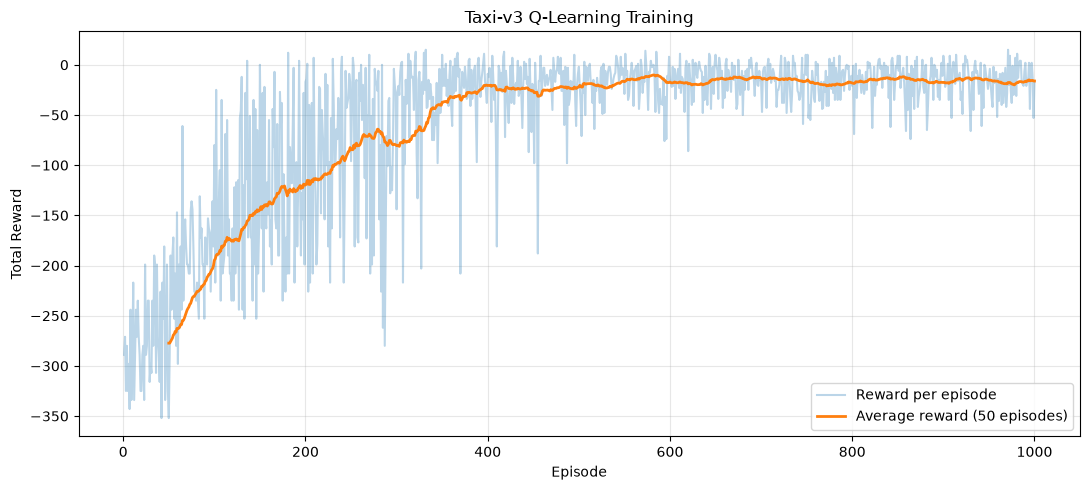

Đã lưu biểu đồ: reward_qtable.png


In [7]:
WINDOW = 50

moving_average = np.convolve(
    episode_rewards,
    np.ones(WINDOW) / WINDOW,
    mode="valid"
)

plt.figure(figsize=(11, 5))

plt.plot(
    range(1, max_episode + 1),
    episode_rewards,
    alpha=0.30,
    label="Reward per episode"
)

plt.plot(
    range(WINDOW, max_episode + 1),
    moving_average,
    linewidth=2,
    label=f"Average reward ({WINDOW} episodes)"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Taxi-v3 Q-Learning Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("reward_qtable.png", dpi=300, bbox_inches="tight")
plt.show()

print("Đã lưu biểu đồ: reward_qtable.png")


## 8. Biểu đồ số bước theo Episode


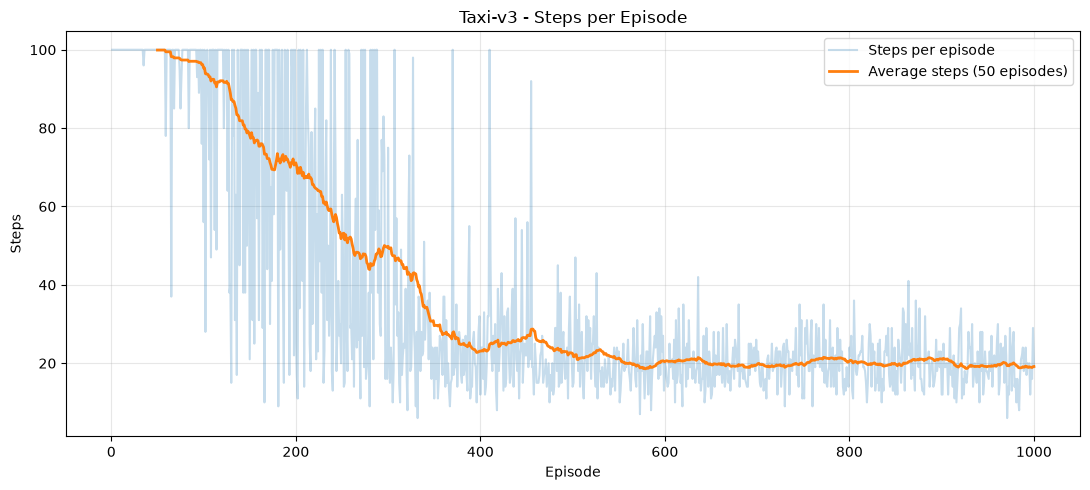

Đã lưu biểu đồ: steps_qtable.png


In [8]:
steps_ma = np.convolve(
    episode_steps,
    np.ones(WINDOW) / WINDOW,
    mode="valid"
)

plt.figure(figsize=(11, 5))

plt.plot(
    range(1, max_episode + 1),
    episode_steps,
    alpha=0.25,
    label="Steps per episode"
)

plt.plot(
    range(WINDOW, max_episode + 1),
    steps_ma,
    linewidth=2,
    label=f"Average steps ({WINDOW} episodes)"
)

plt.xlabel("Episode")
plt.ylabel("Steps")
plt.title("Taxi-v3 - Steps per Episode")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("steps_qtable.png", dpi=300, bbox_inches="tight")
plt.show()

print("Đã lưu biểu đồ: steps_qtable.png")


## 9. Lưu Q-table để GUI sử dụng

Nếu notebook nằm trong `~/chapter6`, file sẽ được lưu vào:

`~/chapter6/taxi_flask/q_table.npy`


In [ ]:
Q_TABLE_PATH = "taxi_flask/q_table.npy"

os.makedirs(os.path.dirname(Q_TABLE_PATH), exist_ok=True)

np.save(Q_TABLE_PATH, Q)

print("=" * 45)
print("ĐÃ LƯU Q-TABLE")
print("=" * 45)
print("File:", Q_TABLE_PATH)
print("Shape:", Q.shape)
print("Min Q:", round(float(np.min(Q)), 3))
print("Max Q:", round(float(np.max(Q)), 3))
print("Số Q-value khác 0:", int(np.count_nonzero(Q)))


## 10. Kiểm tra lại file vừa lưu


In [ ]:
Q_loaded = np.load("taxi_flask/q_table.npy")

print("Load thành công q_table.npy")
print("Shape:", Q_loaded.shape)
print("Q-table giống dữ liệu vừa train:", np.array_equal(Q, Q_loaded))

print("\nVí dụ Q-values của state 123:")
print(Q_loaded[123])

print("Action tốt nhất tại state 123:", int(np.argmax(Q_loaded[123])))


## 11. Lưu số liệu đo để dùng cho báo cáo


In [ ]:
np.savez(
    "qtable_training_metrics.npz",
    episode_rewards=np.array(episode_rewards),
    episode_steps=np.array(episode_steps),
    episode_success=np.array(episode_success),
    training_time=training_time,
    gamma=gamma,
    alpha=alpha,
    epsilon=epsilon,
    max_episode=max_episode,
    max_steps=max_steps,
)

print("Đã lưu số liệu: qtable_training_metrics.npz")


## 12. Test agent sau khi huấn luyện

Phần này đánh giá **policy cuối cùng của Q-table** trên 100 episode.

Khác với lúc training, ở đây **không dùng epsilon và không chọn ngẫu nhiên**.  
Agent luôn chọn:

`action = np.argmax(Q[state, :])`

Các kết quả thu được:
- số bước trung bình sau huấn luyện;
- reward trung bình sau huấn luyện;
- tỷ lệ hoàn thành;
- số bước nhỏ nhất/lớn nhất.


In [9]:
TEST_EPISODES = 100

test_steps = []
test_rewards = []
success_count = 0

for episode in range(TEST_EPISODES):
    state, info = env.reset()

    total_reward = 0
    completed = False

    for step in range(1, max_steps + 1):

        # TEST POLICY CUỐI CÙNG:
        # không random, không epsilon
        action = int(np.argmax(Q[state, :]))

        next_state, reward, terminated, truncated, info = env.step(action)

        total_reward += reward
        state = next_state

        if terminated:
            completed = True
            success_count += 1
            break

        if truncated:
            break

    test_steps.append(step)
    test_rewards.append(total_reward)

avg_test_steps = np.mean(test_steps)
avg_test_reward = np.mean(test_rewards)
success_rate_test = success_count / TEST_EPISODES * 100

print("=" * 50)
print("KẾT QUẢ TEST SAU HUẤN LUYỆN")
print("=" * 50)
print("Số episode test:", TEST_EPISODES)
print("Số bước trung bình:", round(avg_test_steps, 2))
print("Reward trung bình:", round(avg_test_reward, 2))
print("Tỷ lệ hoàn thành:", round(success_rate_test, 2), "%")
print("Số bước nhỏ nhất:", int(np.min(test_steps)))
print("Số bước lớn nhất:", int(np.max(test_steps)))


KẾT QUẢ TEST SAU HUẤN LUYỆN
Số episode test: 100
Số bước trung bình: 14.12
Reward trung bình: 6.67
Tỷ lệ hoàn thành: 99.0 %
Số bước nhỏ nhất: 7
Số bước lớn nhất: 100


## 13. Biểu đồ kết quả test sau huấn luyện

Biểu đồ dưới đây thể hiện số bước cần dùng trong 100 episode test.


In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    range(1, TEST_EPISODES + 1),
    test_steps,
    marker="o",
    markersize=3,
    linewidth=1
)

plt.axhline(
    avg_test_steps,
    linestyle="--",
    label=f"Average = {avg_test_steps:.2f} steps"
)

plt.xlabel("Test episode")
plt.ylabel("Number of steps")
plt.title("Taxi-v3 - Steps After Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "test_steps_after_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu: test_steps_after_training.png")


## 14. Tổng hợp toàn bộ kết quả

Cell này in toàn bộ số liệu quan trọng để có thể chụp màn hình khi demo hoặc đưa vào báo cáo.


In [ ]:
print("=" * 60)
print("        TAXI-v3 Q-LEARNING - TỔNG KẾT")
print("=" * 60)

print("\n[MÔI TRƯỜNG]")
print("States                 :", m)
print("Actions                :", n)
print("Q-table                :", Q.shape)

print("\n[THAM SỐ]")
print("Alpha                  :", alpha)
print("Gamma                  :", gamma)
print("Epsilon                :", epsilon)
print("Training episodes      :", max_episode)
print("Max steps/episode      :", max_steps)

print("\n[KẾT QUẢ TRAINING]")
print("Training time          :", round(training_time, 3), "s")
print("Average reward         :", round(avg_reward_all, 2))
print("Last 100 avg reward    :", round(avg_reward_last100, 2))
print("Avg steps while train  :", round(avg_steps_all, 2))
print("Train completion rate  :", round(success_rate_train, 2), "%")

print("\n[KẾT QUẢ SAU TRAINING]")
print("Test episodes          :", TEST_EPISODES)
print("Average steps          :", round(avg_test_steps, 2))
print("Average reward         :", round(avg_test_reward, 2))
print("Success rate           :", round(success_rate_test, 2), "%")
print("Minimum steps          :", int(np.min(test_steps)))
print("Maximum steps          :", int(np.max(test_steps)))

print("\n[FILE ĐẦU RA]")
print("Q-table                : taxi_flask/q_table.npy")
print("Reward graph           : reward_qtable.png")
print("Training steps graph   : steps_qtable.png")
print("Test steps graph       : test_steps_after_training.png")
print("Metrics                : qtable_training_metrics.npz")
print("Summary                : qtable_results_summary.txt")

print("=" * 60)


## 15. Lưu toàn bộ kết quả đo ra file

File `qtable_results_summary.txt` chứa các số liệu thực tế của lần chạy trên Raspberry Pi.


In [ ]:
summary = f"""TAXI-v3 Q-LEARNING RESULTS
========================================
Environment
States: {m}
Actions: {n}
Q-table: {Q.shape}

Hyperparameters
Alpha: {alpha}
Gamma: {gamma}
Epsilon: {epsilon}
Training episodes: {max_episode}
Max steps: {max_steps}

Training results
Training time: {training_time:.3f} seconds
Average reward: {avg_reward_all:.2f}
Average reward last 100 episodes: {avg_reward_last100:.2f}
Average steps while training: {avg_steps_all:.2f}
Training completion rate: {success_rate_train:.2f} %

Post-training test
Test episodes: {TEST_EPISODES}
Average steps after training: {avg_test_steps:.2f}
Average reward after training: {avg_test_reward:.2f}
Success rate after training: {success_rate_test:.2f} %
Minimum steps: {int(np.min(test_steps))}
Maximum steps: {int(np.max(test_steps))}

Output files
taxi_flask/q_table.npy
reward_qtable.png
steps_qtable.png
test_steps_after_training.png
qtable_training_metrics.npz
"""

with open(
    "qtable_results_summary.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(summary)

print(summary)
print("Đã lưu: qtable_results_summary.txt")


## 16. Lưu metrics đầy đủ gồm cả kết quả test


In [ ]:
np.savez(
    "qtable_all_metrics.npz",

    # Training
    episode_rewards=np.array(episode_rewards),
    episode_steps=np.array(episode_steps),
    episode_success=np.array(episode_success),
    training_time=training_time,

    # Test sau training
    test_steps=np.array(test_steps),
    test_rewards=np.array(test_rewards),
    avg_test_steps=avg_test_steps,
    avg_test_reward=avg_test_reward,
    success_rate_test=success_rate_test,

    # Hyperparameters
    gamma=gamma,
    alpha=alpha,
    epsilon=epsilon,
    max_episode=max_episode,
    max_steps=max_steps,
    test_episodes=TEST_EPISODES,
)

print("Đã lưu toàn bộ metrics: qtable_all_metrics.npz")
